<h1>06. Content Features and Embeddings</h1>

**What we do.** We answer RQ2: under the same five splits and classifier used in notebook 05, we compare the handcrafted graph+community model against a content-only model built from sparse MUSAE profile features, a hybrid model that combines both, and two unsupervised graph embeddings, DeepWalk and Node2Vec, trained without any label, both alone and combined with the handcrafted features.

**What we get.** An ablation table (network-only vs. content-only vs. hybrid), an embedding-comparison table, a t-SNE projection of the learned embeddings colored by label, and the figures backing each of these.

**Why this step matters.** RQ1 already showed that network structure alone is predictive; this notebook asks whether that structure is redundant with, or complementary to, other kinds of information. The result, content is the strongest single source, but the hybrid and embedding-plus-handcrafted models both beat it, is what lets the project claim that network structure carries genuine complementary signal rather than the same information as content in a different format.

In [1]:
from pathlib import Path
import os
import sys
import warnings

def _find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "requirements.txt").exists() and (candidate / "data").exists():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate the project root")

ROOT = _find_project_root(Path.cwd())
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("PYTHONHASHSEED", "0")
warnings.filterwarnings("ignore", category=FutureWarning)
__name__ = "notebook_06"
print(f"Project root: {ROOT}")

Project root: C:\Users\ofir8\OneDrive\Documenten\GitHub\github-social-network


<h2>Content and embedding setup</h2>

DeepWalk and Node2Vec turn nodes into vectors by walking through the graph. We also test content features and combined feature sets. The goal is to see which information source helps most under the same split setup.

<h3>Source code: <code>src/content_features.py</code></h3>

Loads sparse MUSAE content features and implements content-only and hybrid classification models.

**`imports and constants`**

Imports the external libraries and project modules this file depends on, and defines the fixed constants (seeds, budgets, thresholds) shared by every function below.

In [2]:
"""
Content-feature loading and ablation models (features-only / hybrid).

The MUSAE features file (musae_git_features.json) maps each node id to a list
of sparse binary feature ids derived from starred repositories, location,
employer and e-mail. These features are content-based (not network-based),
so comparing them against the network-only models quantifies how much the
network structure itself contributes to prediction.
"""
from pathlib import Path
from typing import Dict, Iterable, List, Tuple

import json

import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

from modeling import _prepare_feature_matrix

**`load_content_features`**

Parses the JSON mapping from node ID to its list of active sparse content-feature indices, and infers the total feature dimensionality from the largest index seen across all nodes.

In [3]:
def load_content_features(path: str | Path) -> Tuple[Dict[int, List[int]], int]:
    """
    Load the sparse binary content features.

    Returns:
        features_dict: node_id -> list of active feature ids
        n_features: total feature dimension (max feature id + 1)
    """
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Missing content features file: {path}")

    with open(path, "r", encoding="utf-8") as f:
        raw = json.load(f)

    features_dict = {int(node): [int(fid) for fid in fids] for node, fids in raw.items()}
    n_features = max((max(fids) for fids in features_dict.values() if fids), default=-1) + 1

    return features_dict, n_features

**`build_content_matrix`**

Builds a compressed sparse row (CSR) binary matrix from the loaded features, with an explicit node order, rather than a dense matrix, since a dense 37,700-by-D array of mostly-zero MUSAE content indicators would be wasteful to allocate and slow to operate on.

In [4]:
def build_content_matrix(
    features_dict: Dict[int, List[int]],
    n_features: int,
    nodes: Iterable[int],
) -> sparse.csr_matrix:
    """Build a sparse binary matrix whose rows are aligned to the given node order."""
    nodes_list = [int(node) for node in nodes]

    row_indices = []
    col_indices = []
    for row_idx, node in enumerate(nodes_list):
        for fid in features_dict.get(node, []):
            row_indices.append(row_idx)
            col_indices.append(fid)

    data = np.ones(len(row_indices), dtype=np.float64)
    matrix = sparse.csr_matrix(
        (data, (row_indices, col_indices)),
        shape=(len(nodes_list), n_features),
    )
    return matrix

**`train_logistic_regression_content_only`**

Fits logistic regression directly on the sparse content matrix, with no graph feature at all, giving the reference point that RQ2 compares network structure against.

In [5]:
def train_logistic_regression_content_only(
    X_train: sparse.csr_matrix,
    y_train: Iterable[int],
    X_test: sparse.csr_matrix,
) -> Tuple[LogisticRegression, np.ndarray, np.ndarray]:
    """Train Logistic Regression on content features only (no network information)."""
    model = LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        solver="liblinear",
        random_state=42,
    )
    model.fit(X_train, np.asarray(list(y_train), dtype=np.int64))

    y_pred = model.predict(X_test)
    y_score = model.predict_proba(X_test)[:, 1]

    return model, y_pred.astype(np.int64), y_score.astype(np.float64)

**`train_logistic_regression_hybrid`**

Scales the dense graph/community features, horizontally stacks them with the sparse content matrix, and fits one logistic-regression model on the combined representation, which is what produces the RQ2 hybrid result.

In [6]:
def train_logistic_regression_hybrid(
    X_train_network: pd.DataFrame,
    X_train_content: sparse.csr_matrix,
    y_train: Iterable[int],
    X_test_network: pd.DataFrame,
    X_test_content: sparse.csr_matrix,
) -> Tuple[LogisticRegression, np.ndarray, np.ndarray]:
    """
    Train Logistic Regression on network features (scaled dense) combined with
    content features (raw sparse binary), stacked side by side.
    """
    x_train_dense = _prepare_feature_matrix(X_train_network)
    x_test_dense = _prepare_feature_matrix(X_test_network, fit_columns=x_train_dense.columns)

    scaler = StandardScaler()
    x_train_scaled = scaler.fit_transform(x_train_dense.to_numpy(dtype=np.float64))
    x_test_scaled = scaler.transform(x_test_dense.to_numpy(dtype=np.float64))

    x_train_combined = sparse.hstack(
        [sparse.csr_matrix(x_train_scaled), X_train_content], format="csr"
    )
    x_test_combined = sparse.hstack(
        [sparse.csr_matrix(x_test_scaled), X_test_content], format="csr"
    )

    model = LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        solver="liblinear",
        random_state=42,
    )
    model.fit(x_train_combined, np.asarray(list(y_train), dtype=np.int64))

    y_pred = model.predict(x_test_combined)
    y_score = model.predict_proba(x_test_combined)[:, 1]

    return model, y_pred.astype(np.int64), y_score.astype(np.float64)

<h3>Source code: <code>src/run_ablation.py</code></h3>

Runs the controlled content vs. network vs. hybrid ablation used to answer RQ2.

**`imports and constants`**

Imports the external libraries and project modules this file depends on, and defines the fixed constants (seeds, budgets, thresholds) shared by every function below.

This module computes its own paths from `__file__`, which Jupyter cells do not define by default. The next cell sets a virtual `__file__` matching this file's real location in the repository, without changing a single line of the copied source below.

In [7]:
__file__ = str(ROOT / 'src/run_ablation.py')

In [8]:
"""
Ablation experiment: how much is the network worth?

Compares three feature families under the exact same protocol used in
run_repeated_experiments (same seeds, same stratified 70/30 splits,
same metrics):

1. Content Only   - MUSAE node features (starred repos / employer / location),
                    no network information at all.
2. Network Only   - the existing Graph + Community feature model.
3. Hybrid         - network features and content features combined.

Outputs:
    outputs/tables/ablation_model_results.csv
    outputs/tables/ablation_model_results_summary.csv
    outputs/figures/ablation_f1_auc_comparison.png
"""
from pathlib import Path
from typing import Sequence

import sys

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SRC_DIR = Path(__file__).resolve().parent
PROJECT_DIR = SRC_DIR.parent
sys.path.insert(0, str(SRC_DIR))

from community_analysis import (
    add_community_features,
    detect_louvain_communities,
    summarize_communities,
)
from content_features import (
    build_content_matrix,
    load_content_features,
    train_logistic_regression_content_only,
    train_logistic_regression_hybrid,
)
from data_loader import load_dataset
from modeling import (
    _merge_node_feature_frames,
    evaluate_predictions,
    extract_graph_neighbor_features,
    prepare_train_test_split,
    train_logistic_regression_graph_features,
)


MODEL_CONTENT_ONLY = "Logistic Regression - Content Features Only"
MODEL_NETWORK_ONLY = "Logistic Regression - Network Only (Graph + Community)"
MODEL_HYBRID = "Logistic Regression - Hybrid (Network + Content)"

**`run_ablation_experiments`**

Runs the content-only, network-only, and hybrid models on the same five fixed splits used everywhere else in the project, so the resulting AUC gaps between them reflect only the information source, not a different evaluation protocol. It follows the same three-step structure on every seed: fit content-only, then network-only (identical to the Graph+Community model from notebook 05), then the hybrid that concatenates both feature sets; and, as in notebook 05, Louvain is computed once per seed and shared across all three fits rather than recomputed.

In [9]:
def run_ablation_experiments(
    data_dir: Path,
    test_size: float = 0.3,
    random_states: Sequence[int] = (42, 7, 21, 84, 123),
) -> pd.DataFrame:
    """Run the three ablation models across repeated stratified splits."""
    G, _, labels_df, labels_dict = load_dataset(data_dir)

    features_dict, n_features = load_content_features(data_dir / "musae_git_features.json")
    print(f"Loaded content features: {len(features_dict)} nodes, {n_features} feature dims")

    # Louvain depends only on graph structure, so we compute it once (same as modeling).
    partition, modularity = detect_louvain_communities(G, random_state=42)
    community_summary_df = summarize_communities(G, labels_dict, partition)
    print(f"Louvain: {len(set(partition.values()))} communities, modularity={modularity:.4f}")

    results_rows = []

    for run_idx, random_state in enumerate(random_states, start=1):
        print(f"[run {run_idx}/{len(random_states)}] random_state={random_state}")

        train_nodes, test_nodes, y_train, y_test = prepare_train_test_split(
            labels_df=labels_df,
            test_size=test_size,
            random_state=int(random_state),
        )
        nodes_for_features = list(train_nodes) + list(test_nodes)

        # --- Content Only ---
        X_train_content = build_content_matrix(features_dict, n_features, train_nodes)
        X_test_content = build_content_matrix(features_dict, n_features, test_nodes)

        _, y_pred_content, y_score_content = train_logistic_regression_content_only(
            X_train=X_train_content,
            y_train=y_train,
            X_test=X_test_content,
        )
        metrics_content = evaluate_predictions(y_test, y_pred_content, y_score_content)

        # --- Network Only (Graph + Community, identical to the existing model) ---
        graph_features_df = extract_graph_neighbor_features(
            G=G,
            labels_dict=labels_dict,
            train_nodes=train_nodes,
            nodes=nodes_for_features,
        ).drop_duplicates(subset=["node_id"])

        community_features_df = add_community_features(
            G=G,
            labels_dict=labels_dict,
            train_nodes=train_nodes,
            nodes=nodes_for_features,
            partition=partition,
            community_summary_df=community_summary_df,
        ).drop_duplicates(subset=["node_id"])

        combined_features_df = _merge_node_feature_frames(graph_features_df, community_features_df)
        combined_features_indexed = combined_features_df.set_index("node_id")

        X_train_network = combined_features_indexed.reindex(train_nodes).reset_index()
        X_test_network = combined_features_indexed.reindex(test_nodes).reset_index()

        _, y_pred_network, y_score_network = train_logistic_regression_graph_features(
            X_train=X_train_network,
            y_train=y_train,
            X_test=X_test_network,
        )
        metrics_network = evaluate_predictions(y_test, y_pred_network, y_score_network)

        # --- Hybrid (Network + Content) ---
        _, y_pred_hybrid, y_score_hybrid = train_logistic_regression_hybrid(
            X_train_network=X_train_network,
            X_train_content=X_train_content,
            y_train=y_train,
            X_test_network=X_test_network,
            X_test_content=X_test_content,
        )
        metrics_hybrid = evaluate_predictions(y_test, y_pred_hybrid, y_score_hybrid)

        for model_name, metrics in (
            (MODEL_CONTENT_ONLY, metrics_content),
            (MODEL_NETWORK_ONLY, metrics_network),
            (MODEL_HYBRID, metrics_hybrid),
        ):
            results_rows.append(
                {
                    "run": run_idx,
                    "random_state": int(random_state),
                    "model": model_name,
                    "accuracy": metrics["accuracy"],
                    "balanced_accuracy": metrics["balanced_accuracy"],
                    "precision": metrics["precision"],
                    "recall": metrics["recall"],
                    "f1": metrics["f1"],
                    "macro_f1": metrics["macro_f1"],
                    "weighted_f1": metrics["weighted_f1"],
                    "roc_auc": metrics["roc_auc"],
                }
            )
            print(
                f"    {model_name}: F1={metrics['f1']:.4f} "
                f"MacroF1={metrics['macro_f1']:.4f} ROC-AUC={metrics['roc_auc']:.4f}"
            )

    return pd.DataFrame(results_rows)

**`summarize_ablation_results`**

Aggregates the repeated ablation results into one mean/std row per model, the table RQ2's content-vs-network-vs-hybrid comparison is built from.

In [10]:
def summarize_ablation_results(results_df: pd.DataFrame) -> pd.DataFrame:
    """Aggregate repeated ablation results per model (mean/std)."""
    metric_columns = [
        "accuracy",
        "balanced_accuracy",
        "precision",
        "recall",
        "f1",
        "macro_f1",
        "weighted_f1",
        "roc_auc",
    ]
    summary_df = results_df.groupby("model", as_index=False)[metric_columns].agg(["mean", "std"])
    summary_df.columns = [
        "model" if col == ("model", "") else f"{col[0]}_{col[1]}" for col in summary_df.columns
    ]
    return summary_df

**`plot_ablation_comparison`**

Saves the bar chart comparing Macro F1 and ROC-AUC across the three ablation models.

In [11]:
def plot_ablation_comparison(results_df: pd.DataFrame, output_path: Path) -> None:
    """Bar chart of F1 / Macro F1 / ROC-AUC per ablation model with std error bars."""
    model_order = [MODEL_CONTENT_ONLY, MODEL_NETWORK_ONLY, MODEL_HYBRID]
    short_names = ["Content Only", "Network Only", "Hybrid"]
    metrics = [("f1", "F1 (ML class)"), ("macro_f1", "Macro F1"), ("roc_auc", "ROC-AUC")]

    fig, axes = plt.subplots(1, len(metrics), figsize=(15, 5), sharey=False)
    colors = ["#d1884f", "#4f7bd1", "#5aa469"]

    for ax, (metric, title) in zip(axes, metrics):
        means = [results_df.loc[results_df["model"] == m, metric].mean() for m in model_order]
        stds = [results_df.loc[results_df["model"] == m, metric].std() for m in model_order]

        bars = ax.bar(short_names, means, yerr=stds, capsize=5, color=colors)
        for bar, mean in zip(bars, means):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                mean + 0.01,
                f"{mean:.3f}",
                ha="center",
                va="bottom",
                fontsize=10,
            )
        ax.set_title(title)
        ax.set_ylim(0, 1.05)
        ax.grid(axis="y", alpha=0.3)

    fig.suptitle("Ablation: What Is the Network Worth? (mean over 5 splits)", fontsize=13)
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.close(fig)

**`main`**

Runs the content-only, network-only, and hybrid ablation models over the same five splits and saves the ablation summary table and figure.

In [12]:
def main() -> None:
    data_dir = PROJECT_DIR / "data"
    tables_dir = PROJECT_DIR / "outputs" / "tables"
    figures_dir = PROJECT_DIR / "outputs" / "figures"
    tables_dir.mkdir(parents=True, exist_ok=True)
    figures_dir.mkdir(parents=True, exist_ok=True)

    results_df = run_ablation_experiments(data_dir)

    results_path = tables_dir / "ablation_model_results.csv"
    results_df.to_csv(results_path, index=False)
    print(f"Saved: {results_path}")

    summary_df = summarize_ablation_results(results_df)
    summary_path = tables_dir / "ablation_model_results_summary.csv"
    summary_df.to_csv(summary_path, index=False)
    print(f"Saved: {summary_path}")

    figure_path = figures_dir / "ablation_f1_auc_comparison.png"
    plot_ablation_comparison(results_df, figure_path)
    print(f"Saved: {figure_path}")

    print("\n=== Summary (mean over splits) ===")
    display_cols = ["model", "f1_mean", "macro_f1_mean", "roc_auc_mean", "recall_mean", "precision_mean"]
    available = [c for c in display_cols if c in summary_df.columns]
    print(summary_df[available].to_string(index=False))

**`__main__ guard`**

Keeps the original command-line entry guard from the source file; it stays inactive here because the run cell below calls the pipeline directly.

In [13]:
if __name__ == "__main__":
    main()

<h2>Run this step</h2>

Run content-only, network-only, and hybrid models on the five fixed splits.

In [14]:
from run_ablation import main as run_ablation

run_ablation()

Loaded content features: 37700 nodes, 4005 feature dims


Louvain: 31 communities, modularity=0.4534
[run 1/5] random_state=42


    Logistic Regression - Content Features Only: F1=0.6937 MacroF1=0.7863 ROC-AUC=0.8860
    Logistic Regression - Network Only (Graph + Community): F1=0.6671 MacroF1=0.7693 ROC-AUC=0.8675
    Logistic Regression - Hybrid (Network + Content): F1=0.7034 MacroF1=0.7934 ROC-AUC=0.8948
[run 2/5] random_state=7


    Logistic Regression - Content Features Only: F1=0.7079 MacroF1=0.7958 ROC-AUC=0.8934
    Logistic Regression - Network Only (Graph + Community): F1=0.6790 MacroF1=0.7759 ROC-AUC=0.8732
    Logistic Regression - Hybrid (Network + Content): F1=0.7160 MacroF1=0.8020 ROC-AUC=0.9012
[run 3/5] random_state=21


    Logistic Regression - Content Features Only: F1=0.6954 MacroF1=0.7880 ROC-AUC=0.8857
    Logistic Regression - Network Only (Graph + Community): F1=0.6685 MacroF1=0.7707 ROC-AUC=0.8665
    Logistic Regression - Hybrid (Network + Content): F1=0.7013 MacroF1=0.7925 ROC-AUC=0.8941
[run 4/5] random_state=84


    Logistic Regression - Content Features Only: F1=0.7030 MacroF1=0.7925 ROC-AUC=0.8934
    Logistic Regression - Network Only (Graph + Community): F1=0.6792 MacroF1=0.7782 ROC-AUC=0.8768
    Logistic Regression - Hybrid (Network + Content): F1=0.7166 MacroF1=0.8022 ROC-AUC=0.9027
[run 5/5] random_state=123


    Logistic Regression - Content Features Only: F1=0.6940 MacroF1=0.7864 ROC-AUC=0.8851
    Logistic Regression - Network Only (Graph + Community): F1=0.6647 MacroF1=0.7678 ROC-AUC=0.8631
    Logistic Regression - Hybrid (Network + Content): F1=0.7051 MacroF1=0.7949 ROC-AUC=0.8947
Saved: C:\Users\ofir8\OneDrive\Documenten\GitHub\github-social-network\outputs\tables\ablation_model_results.csv
Saved: C:\Users\ofir8\OneDrive\Documenten\GitHub\github-social-network\outputs\tables\ablation_model_results_summary.csv


Saved: C:\Users\ofir8\OneDrive\Documenten\GitHub\github-social-network\outputs\figures\ablation_f1_auc_comparison.png

=== Summary (mean over splits) ===
                                                 model  f1_mean  macro_f1_mean  roc_auc_mean  recall_mean  precision_mean
           Logistic Regression - Content Features Only 0.698807       0.789794      0.888715     0.767077        0.641710
      Logistic Regression - Hybrid (Network + Content) 0.708473       0.797004      0.897518     0.773238        0.653741
Logistic Regression - Network Only (Graph + Community) 0.671694       0.772363      0.869393     0.725120        0.625680


Then we read the saved tables and figures.

<h3>Source code: <code>src/embeddings.py</code></h3>

Implements DeepWalk and Node2Vec random walks, skip-gram training, and conversion to feature frames.

**`imports and constants`**

Imports the external libraries and project modules this file depends on, and defines the fixed constants (seeds, budgets, thresholds) shared by every function below.

In [15]:
"""
DeepWalk and Node2Vec node embeddings.

DeepWalk treats truncated random walks over the graph as "sentences" and
learns node embeddings with Word2Vec (skip-gram), following the idea from
the course DeepWalk tutorial, scaled up to the full GitHub network.

The embeddings are unsupervised and depend only on graph structure, so they
respect the project's network-only principle: no labels and no content
features are used at any point of the embedding computation.
"""
import random
from typing import Dict, List

import networkx as nx
import numpy as np
import pandas as pd
from gensim.models import Word2Vec

**`generate_random_walks`**

Generates DeepWalk's uniform random walks, choosing each next step from a node's neighbors with equal probability. Cost is roughly O(V * num_walks * walk_length); the function pre-computes and caches every node's neighbor list once before the walk loop starts, because repeatedly calling G.neighbors(node) fresh inside the innermost step of millions of walk steps would otherwise dominate the total runtime. This uniform sampling is what distinguishes DeepWalk from Node2Vec's biased alternative below.

In [16]:
def generate_random_walks(
    G: nx.Graph,
    num_walks: int = 10,
    walk_length: int = 80,
    seed: int = 42,
) -> List[List[str]]:
    """
    Generate uniform truncated random walks from every node.

    Returns walks as lists of string node ids (gensim expects string tokens).
    """
    rng = random.Random(seed)

    # Precompute neighbor lists once; per-step attribute access would dominate runtime.
    neighbors: Dict[int, List[int]] = {node: list(G.neighbors(node)) for node in G.nodes()}

    nodes = list(G.nodes())
    walks: List[List[str]] = []

    for _ in range(num_walks):
        rng.shuffle(nodes)
        for start in nodes:
            walk = [start]
            current = start
            for _ in range(walk_length - 1):
                current_neighbors = neighbors[current]
                if not current_neighbors:
                    break
                current = current_neighbors[rng.randrange(len(current_neighbors))]
                walk.append(current)
            walks.append([str(node) for node in walk])

    return walks

**`generate_node2vec_walks`**

Generates Node2Vec's second-order biased walks, where the transition probability depends on both the current and the previous node via the p and q parameters: p controls how likely the walk is to immediately return to where it came from, and q controls how far it is willing to explore outward. This lets the same walk-based method interpolate between behaving like a breadth-first and a depth-first exploration of a node's neighborhood.

In [17]:
def generate_node2vec_walks(
    G: nx.Graph,
    num_walks: int = 5,
    walk_length: int = 40,
    p: float = 1.0,
    q: float = 2.0,
    seed: int = 42,
) -> List[List[str]]:
    """Generate second-order biased walks using the Node2Vec transition rule.

    ``p`` controls immediate returns and ``q`` controls outward exploration.
    The default ``q=2`` gives a modest breadth-first bias that is appropriate
    for testing whether structurally similar neighborhoods help field
    classification.  The implementation is deterministic for a fixed graph
    order and seed.
    """
    if p <= 0 or q <= 0:
        raise ValueError("Node2Vec parameters p and q must be positive.")

    rng = random.Random(seed)
    neighbors: Dict[int, List[int]] = {
        int(node): [int(nbr) for nbr in G.neighbors(node)] for node in G.nodes()
    }
    neighbor_sets = {node: set(nbrs) for node, nbrs in neighbors.items()}
    nodes = [int(node) for node in G.nodes()]
    walks: List[List[str]] = []

    for _ in range(num_walks):
        rng.shuffle(nodes)
        for start in nodes:
            walk = [start]
            while len(walk) < walk_length:
                current = walk[-1]
                candidates = neighbors[current]
                if not candidates:
                    break
                if len(walk) == 1:
                    next_node = candidates[rng.randrange(len(candidates))]
                else:
                    previous = walk[-2]
                    weights = []
                    previous_neighbors = neighbor_sets[previous]
                    for candidate in candidates:
                        if candidate == previous:
                            weights.append(1.0 / p)
                        elif candidate in previous_neighbors:
                            weights.append(1.0)
                        else:
                            weights.append(1.0 / q)
                    next_node = rng.choices(candidates, weights=weights, k=1)[0]
                walk.append(next_node)
            walks.append([str(node) for node in walk])
    return walks

**`train_deepwalk`**

Trains a skip-gram Word2Vec model on the uniform walks with a single worker thread, which trades training speed for much more deterministic output across repeated runs with the same seed.

In [18]:
def train_deepwalk(
    walks: List[List[str]],
    dimensions: int = 128,
    window: int = 10,
    epochs: int = 5,
    seed: int = 42,
    workers: int = 1,
) -> Word2Vec:
    """
    Train skip-gram Word2Vec over the random walks.

    workers=1 keeps training deterministic for a fixed seed (multi-worker
    training is faster but yields slightly different vectors on every run,
    which would make all downstream numbers non-reproducible). For full
    determinism run with the environment variable PYTHONHASHSEED=0.
    """
    model = Word2Vec(
        sentences=walks,
        vector_size=dimensions,
        window=window,
        min_count=0,
        sg=1,  # Skip-gram, as in DeepWalk
        workers=workers,
        seed=seed,
        epochs=epochs,
    )
    return model

**`train_node2vec`**

Trains the identical skip-gram objective as train_deepwalk, but on the p,q-biased walks instead, isolating the walk-generation strategy as the only difference between the two learned representations that RQ2 compares.

In [19]:
def train_node2vec(
    walks: List[List[str]],
    dimensions: int = 64,
    window: int = 5,
    epochs: int = 5,
    seed: int = 42,
    workers: int = 1,
) -> Word2Vec:
    """Train skip-gram embeddings from Node2Vec biased walks."""
    return Word2Vec(
        sentences=walks,
        vector_size=dimensions,
        window=window,
        min_count=0,
        sg=1,
        workers=workers,
        seed=seed,
        epochs=epochs,
    )

**`embeddings_to_frame`**

Reads the learned vector for every requested node out of the trained Word2Vec model and returns them as one ID-aligned DataFrame, ready to be merged with other feature tables or handed to a classifier.

In [20]:
def embeddings_to_frame(model: Word2Vec, nodes: List[int]) -> pd.DataFrame:
    """
    Extract embeddings for the given nodes into a DataFrame with a node_id
    column, compatible with the existing feature-frame merging utilities.
    """
    dimensions = model.wv.vector_size
    rows = np.zeros((len(nodes), dimensions), dtype=np.float64)
    for i, node in enumerate(nodes):
        key = str(int(node))
        if key in model.wv:
            rows[i] = model.wv[key]

    frame = pd.DataFrame(rows, columns=[f"deepwalk_{d}" for d in range(dimensions)])
    frame.insert(0, "node_id", [int(node) for node in nodes])
    return frame

<h3>Source code: <code>src/run_embeddings.py</code></h3>

Trains DeepWalk and Node2Vec, evaluates them, and builds the t-SNE and representation-comparison figures.

**`imports and constants`**

Imports the external libraries and project modules this file depends on, and defines the fixed constants (seeds, budgets, thresholds) shared by every function below.

This module computes its own paths from `__file__`, which Jupyter cells do not define by default. The next cell sets a virtual `__file__` matching this file's real location in the repository, without changing a single line of the copied source below.

In [21]:
__file__ = str(ROOT / 'src/run_embeddings.py')

In [22]:
"""DeepWalk and Node2Vec classification under one fair repeated protocol."""

from pathlib import Path
import sys
import time

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.manifold import TSNE

SRC_DIR = Path(__file__).resolve().parent
PROJECT_DIR = SRC_DIR.parent
sys.path.insert(0, str(SRC_DIR))

from community_analysis import (
    add_community_features,
    detect_louvain_communities,
    summarize_communities,
)
from data_loader import load_dataset
from embeddings import (
    embeddings_to_frame,
    generate_node2vec_walks,
    generate_random_walks,
    train_deepwalk,
    train_node2vec,
)
from modeling import (
    _merge_node_feature_frames,
    evaluate_predictions,
    extract_graph_neighbor_features,
    prepare_train_test_split,
    train_logistic_regression_graph_features,
)


SEEDS = (42, 7, 21, 84, 123)
NUM_WALKS = 3
WALK_LENGTH = 40
DIMENSIONS = 64
WINDOW = 5
EPOCHS = 5
NODE2VEC_P = 1.0
NODE2VEC_Q = 2.0
TSNE_SAMPLE = 4_000

EMBEDDING_MODELS = (
    "Logistic Regression - DeepWalk",
    "Logistic Regression - DeepWalk + Graph + Community",
    "Logistic Regression - Node2Vec",
    "Logistic Regression - Node2Vec + Graph + Community",
)
METRICS = (
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1",
    "macro_f1",
    "weighted_f1",
    "roc_auc",
)

**`_learn_embeddings`**

Trains DeepWalk and Node2Vec back to back with identical walk and Word2Vec budgets (3 walks per node, length 40, 64 dimensions, window 5, 5 epochs) so the only difference between the two saved embeddings is the walk-generation strategy, and saves both as compressed .npz files under outputs/embeddings.

In [23]:
def _learn_embeddings(
    G,
    all_nodes: np.ndarray,
    embeddings_dir: Path,
) -> dict[str, pd.DataFrame]:
    """Train both methods with identical walk and Word2Vec budgets."""
    frames: dict[str, pd.DataFrame] = {}

    started = time.time()
    deepwalk_walks = generate_random_walks(
        G, num_walks=NUM_WALKS, walk_length=WALK_LENGTH, seed=42
    )
    deepwalk_model = train_deepwalk(
        deepwalk_walks,
        dimensions=DIMENSIONS,
        window=WINDOW,
        epochs=EPOCHS,
        seed=42,
    )
    frames["DeepWalk"] = embeddings_to_frame(
        deepwalk_model, list(all_nodes)
    )
    np.savez_compressed(
        embeddings_dir / "deepwalk_64.npz",
        nodes=all_nodes,
        embeddings=frames["DeepWalk"].drop(columns=["node_id"]).to_numpy(),
    )
    del deepwalk_walks, deepwalk_model
    print(f"DeepWalk trained in {time.time() - started:.1f}s")

    started = time.time()
    node2vec_walks = generate_node2vec_walks(
        G,
        num_walks=NUM_WALKS,
        walk_length=WALK_LENGTH,
        p=NODE2VEC_P,
        q=NODE2VEC_Q,
        seed=42,
    )
    node2vec_model = train_node2vec(
        node2vec_walks,
        dimensions=DIMENSIONS,
        window=WINDOW,
        epochs=EPOCHS,
        seed=42,
    )
    frames["Node2Vec"] = embeddings_to_frame(
        node2vec_model, list(all_nodes)
    )
    np.savez_compressed(
        embeddings_dir / "node2vec_64.npz",
        nodes=all_nodes,
        embeddings=frames["Node2Vec"].drop(columns=["node_id"]).to_numpy(),
    )
    del node2vec_walks, node2vec_model
    print(f"Node2Vec trained in {time.time() - started:.1f}s")
    return frames

**`_evaluate`**

Builds graph+community, DeepWalk, and Node2Vec feature sets, alone and combined with the handcrafted features, and runs the same repeated logistic-regression protocol on each, so every representation in RQ2 is scored under identical splits and metrics.

In [24]:
def _evaluate(
    G,
    labels_df: pd.DataFrame,
    labels_dict: dict[int, int],
    embedding_frames: dict[str, pd.DataFrame],
) -> pd.DataFrame:
    partition, _ = detect_louvain_communities(G, random_state=42)
    community_df = summarize_communities(G, labels_dict, partition)
    indexed_embeddings = {
        name: frame.set_index("node_id")
        for name, frame in embedding_frames.items()
    }
    rows: list[dict] = []

    for run_idx, seed in enumerate(SEEDS, start=1):
        train_nodes, test_nodes, y_train, y_test = prepare_train_test_split(
            labels_df, test_size=0.30, random_state=int(seed)
        )
        feature_nodes = list(train_nodes) + list(test_nodes)
        graph_features = extract_graph_neighbor_features(
            G, labels_dict, train_nodes, feature_nodes
        ).drop_duplicates("node_id")
        community_features = add_community_features(
            G,
            labels_dict,
            train_nodes,
            feature_nodes,
            partition,
            community_df,
        ).drop_duplicates("node_id")
        handcrafted = _merge_node_feature_frames(
            graph_features, community_features
        )

        for method in ("DeepWalk", "Node2Vec"):
            embedding_df = embedding_frames[method]
            embedding_indexed = indexed_embeddings[method]
            X_train_embedding = embedding_indexed.reindex(
                train_nodes
            ).reset_index()
            X_test_embedding = embedding_indexed.reindex(
                test_nodes
            ).reset_index()
            _, pred_embedding, score_embedding = (
                train_logistic_regression_graph_features(
                    X_train_embedding, y_train, X_test_embedding
                )
            )
            embedding_metrics = evaluate_predictions(
                y_test, pred_embedding, score_embedding
            )

            combined = _merge_node_feature_frames(
                handcrafted, embedding_df
            ).set_index("node_id")
            X_train_combined = combined.reindex(train_nodes).reset_index()
            X_test_combined = combined.reindex(test_nodes).reset_index()
            _, pred_combined, score_combined = (
                train_logistic_regression_graph_features(
                    X_train_combined, y_train, X_test_combined
                )
            )
            combined_metrics = evaluate_predictions(
                y_test, pred_combined, score_combined
            )

            for model_name, metrics in (
                (f"Logistic Regression - {method}", embedding_metrics),
                (
                    f"Logistic Regression - {method} + Graph + Community",
                    combined_metrics,
                ),
            ):
                rows.append(
                    {
                        "run": int(run_idx),
                        "random_state": int(seed),
                        "model": model_name,
                        **{metric: float(metrics[metric]) for metric in METRICS},
                    }
                )
    return pd.DataFrame(rows)

**`_summarize`, `_plot_representation_comparison`, `_plot_tsne`, `main`**

`_summarize` aggregates the repeated embedding-classification results into one mean/std row per representation, sorted by mean ROC-AUC. `_plot_representation_comparison` plots Macro F1 and ROC-AUC across the handcrafted, DeepWalk, Node2Vec, and hybrid representations on the same axes. `_plot_tsne` projects a 4,000-node sample of the learned embeddings to two dimensions and colors the points by field label.

`main` trains DeepWalk and Node2Vec, evaluates four representation-based classifiers, and saves the embedding files, summary table, t-SNE figure, and representation-comparison figure.

In [25]:
def _summarize(results_df: pd.DataFrame) -> pd.DataFrame:
    summary = results_df.groupby("model", as_index=False)[list(METRICS)].agg(
        ["mean", "std"]
    )
    summary.columns = [
        "model" if column == ("model", "") else f"{column[0]}_{column[1]}"
        for column in summary.columns
    ]
    return summary.sort_values("roc_auc_mean").reset_index(drop=True)


def _plot_representation_comparison(
    embedding_summary: pd.DataFrame,
    ablation_summary: pd.DataFrame,
    output_path: Path,
) -> None:
    sources = [
        (
            "Handcrafted\nnetwork",
            ablation_summary[
                ablation_summary["model"].str.contains(
                    "Network Only", regex=False
                )
            ].iloc[0],
        ),
        (
            "Content",
            ablation_summary[
                ablation_summary["model"].str.contains(
                    "Content Features Only", regex=False
                )
            ].iloc[0],
        ),
        (
            "DeepWalk",
            embedding_summary[
                embedding_summary["model"]
                == "Logistic Regression - DeepWalk"
            ].iloc[0],
        ),
        (
            "Node2Vec",
            embedding_summary[
                embedding_summary["model"]
                == "Logistic Regression - Node2Vec"
            ].iloc[0],
        ),
        (
            "Hybrid\nnetwork + content",
            ablation_summary[
                ablation_summary["model"].str.contains(
                    "Hybrid", regex=False
                )
            ].iloc[0],
        ),
    ]
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.3))
    colors = ["#315C8D", "#D57837", "#6E5AA3", "#4F8A5B", "#2A7F78"]
    for ax, metric, title in (
        (axes[0], "macro_f1", "Macro F1"),
        (axes[1], "roc_auc", "ROC-AUC"),
    ):
        values = [float(row[f"{metric}_mean"]) for _, row in sources]
        errors = [float(row[f"{metric}_std"]) for _, row in sources]
        bars = ax.bar(
            [label for label, _ in sources],
            values,
            yerr=errors,
            capsize=4,
            color=colors,
        )
        for bar, value in zip(bars, values):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                value + 0.010,
                f"{value:.3f}",
                ha="center",
                fontsize=9,
            )
        ax.set_title(title)
        ax.set_ylim(0.65, 0.93)
        ax.grid(axis="y", alpha=0.25)
    fig.suptitle(
        "Manual, learned and content representations\n"
        "Same five splits and Logistic Regression evaluation"
    )
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


def _plot_tsne(
    embedding_frames: dict[str, pd.DataFrame],
    labels_df: pd.DataFrame,
    output_path: Path,
) -> None:
    rng = np.random.default_rng(42)
    sample_idx = rng.choice(
        len(labels_df), size=min(TSNE_SAMPLE, len(labels_df)), replace=False
    )
    labels = labels_df["label"].to_numpy(dtype=np.int64)[sample_idx]
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
    for ax, method in zip(axes, ("DeepWalk", "Node2Vec")):
        matrix = embedding_frames[method].drop(
            columns=["node_id"]
        ).to_numpy(dtype=np.float64)
        coordinates = TSNE(
            n_components=2,
            learning_rate="auto",
            init="pca",
            random_state=42,
        ).fit_transform(matrix[sample_idx])
        for label, field, color in (
            (0, "Web", "#315C8D"),
            (1, "Machine Learning", "#D57837"),
        ):
            mask = labels == label
            ax.scatter(
                coordinates[mask, 0],
                coordinates[mask, 1],
                s=6,
                alpha=0.45,
                color=color,
                linewidths=0,
                label=field,
            )
        ax.set_title(method)
        ax.set_xticks([])
        ax.set_yticks([])
    axes[1].legend(markerscale=3, loc="best")
    fig.suptitle(
        f"t-SNE view of unsupervised graph embeddings ({len(sample_idx):,} developers)"
    )
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


def main() -> None:
    data_dir = PROJECT_DIR / "data"
    tables_dir = PROJECT_DIR / "outputs" / "tables"
    figures_dir = PROJECT_DIR / "outputs" / "figures"
    embeddings_dir = PROJECT_DIR / "outputs" / "embeddings"
    for directory in (tables_dir, figures_dir, embeddings_dir):
        directory.mkdir(parents=True, exist_ok=True)

    G, _, labels_df, labels_dict = load_dataset(data_dir)
    all_nodes = labels_df["id"].to_numpy(dtype=np.int64)
    frames = _learn_embeddings(G, all_nodes, embeddings_dir)
    results_df = _evaluate(G, labels_df, labels_dict, frames)
    if set(results_df["model"]) != set(EMBEDDING_MODELS):
        raise AssertionError("Embedding model names do not match the declared set.")
    summary_df = _summarize(results_df)
    results_df.to_csv(
        tables_dir / "embedding_classification_results.csv", index=False
    )
    summary_df.to_csv(
        tables_dir / "embedding_classification_summary.csv", index=False
    )

    ablation_summary = pd.read_csv(
        tables_dir / "ablation_model_results_summary.csv"
    )
    _plot_representation_comparison(
        summary_df,
        ablation_summary,
        figures_dir / "representation_comparison.png",
    )
    _plot_tsne(
        frames, labels_df, figures_dir / "embedding_tsne.png"
    )
    print(summary_df.to_string(index=False))

**`__main__ guard`**

Keeps the original command-line entry guard from the source file; it stays inactive here because the run cell below calls the pipeline directly.

In [26]:
if __name__ == "__main__":
    main()

<h2>Run this step</h2>

Train DeepWalk and Node2Vec, save their vectors, and evaluate four embedding-based classifiers.

In [27]:
from run_embeddings import main as run_embeddings

run_embeddings()

DeepWalk trained in 96.6s


Node2Vec trained in 373.9s


                                             model  accuracy_mean  accuracy_std  balanced_accuracy_mean  balanced_accuracy_std  precision_mean  precision_std  recall_mean  recall_std  f1_mean   f1_std  macro_f1_mean  macro_f1_std  weighted_f1_mean  weighted_f1_std  roc_auc_mean  roc_auc_std
                    Logistic Regression - Node2Vec       0.820088      0.004381                0.807901               0.004737        0.620374       0.007667     0.782683    0.007525 0.692120 0.006515       0.782514      0.004844          0.826201         0.004078      0.890272     0.004724
                    Logistic Regression - DeepWalk       0.820495      0.003372                0.808599               0.005520        0.620835       0.004703     0.783984    0.010407 0.692926 0.006648       0.783052      0.004421          0.826610         0.003362      0.890676     0.004490
Logistic Regression - Node2Vec + Graph + Community       0.827639      0.004484                0.815311               0.0053

Then we read the saved tables and figures.

<h3>Table: <code>outputs/tables/ablation_model_results_summary.csv</code></h3>

Controlled comparison of content, network, and hybrid information.

In [28]:
ablation = pd.read_csv(ROOT / 'outputs/tables/ablation_model_results_summary.csv')
display(ablation[['model', 'f1_mean', 'macro_f1_mean', 'roc_auc_mean', 'roc_auc_std']].round(4))

,model,f1_mean,macro_f1_mean,roc_auc_mean,roc_auc_std
0,Logistic Regression - Content Features Only,0.6988,0.7898,0.8887,0.0043
1,Logistic Regression - Hybrid (Network + Content),0.7085,0.7970,0.8975,0.0041
2,Logistic Regression - Network Only (Graph + Co...,0.6717,0.7724,0.8694,0.0055


**Conclusion.** Content is stronger than handcrafted network features alone, while the hybrid result shows that the graph contributes complementary signal.

<h3>Figure: <code>ablation_f1_auc_comparison.png</code></h3>

This figure compares F1 and ROC-AUC for the three information families in the preceding table.

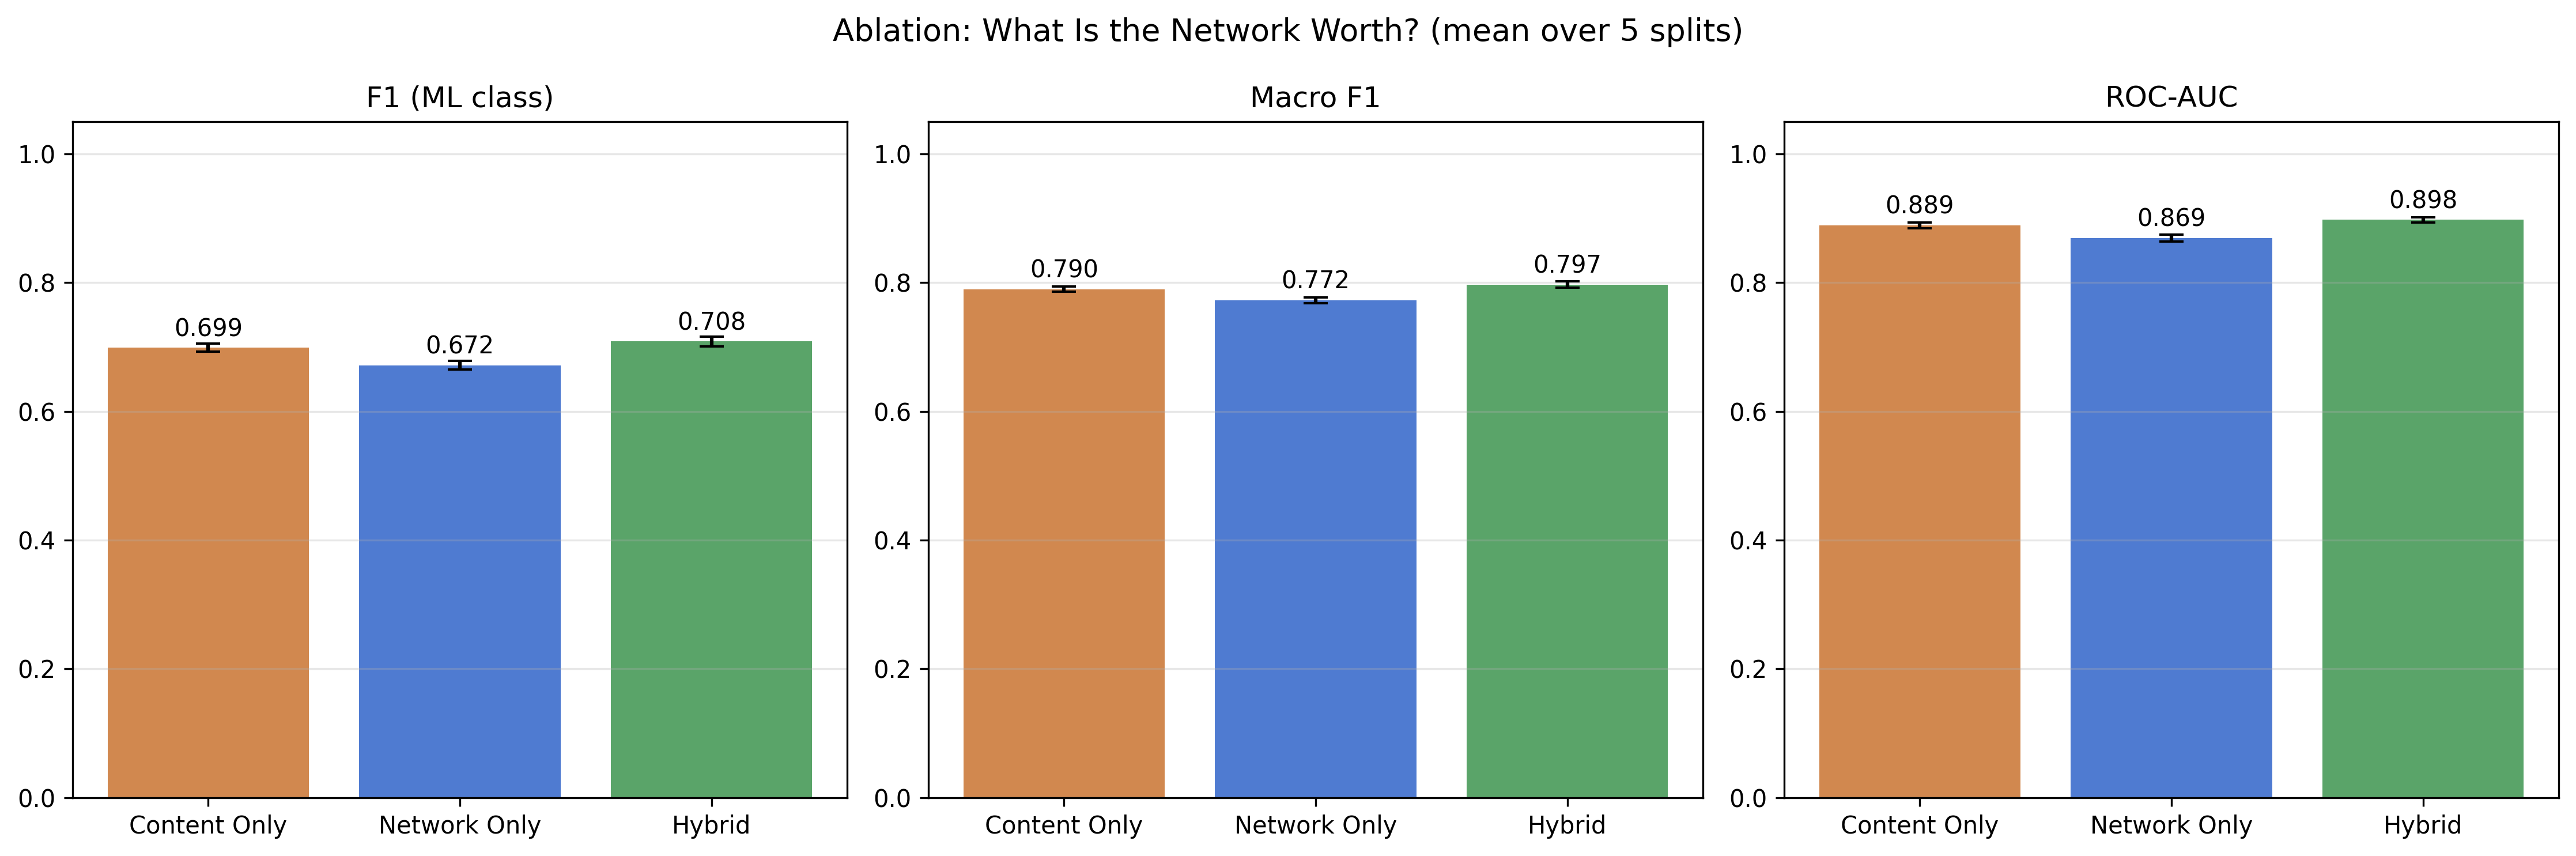

In [29]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'outputs/figures/ablation_f1_auc_comparison.png')))

**Figure note.** The hybrid model leads both views, supporting complementarity rather than a claim that either network or content fully subsumes the other.

<h3>Table: <code>outputs/tables/embedding_classification_summary.csv</code></h3>

DeepWalk and Node2Vec alone and combined with handcrafted graph and community features.

In [30]:
embedding_results = pd.read_csv(ROOT / 'outputs/tables/embedding_classification_summary.csv')
display(embedding_results[['model', 'f1_mean', 'macro_f1_mean', 'roc_auc_mean', 'roc_auc_std']].round(4))

,model,f1_mean,macro_f1_mean,roc_auc_mean,roc_auc_std
0,Logistic Regression - Node2Vec,0.6921,0.7825,0.8903,0.0047
1,Logistic Regression - DeepWalk,0.6929,0.7831,0.8907,0.0045
2,Logistic Regression - Node2Vec + Graph + Commu...,0.7031,0.7908,0.8990,0.0048
3,Logistic Regression - DeepWalk + Graph + Commu...,0.7034,0.7910,0.8996,0.0047


**Conclusion.** Both learned representations are strong, and adding handcrafted structure yields a small further gain.

<h3>Figure: <code>representation_comparison.png</code></h3>

This figure compares the four learned-representation models summarized in the preceding table.

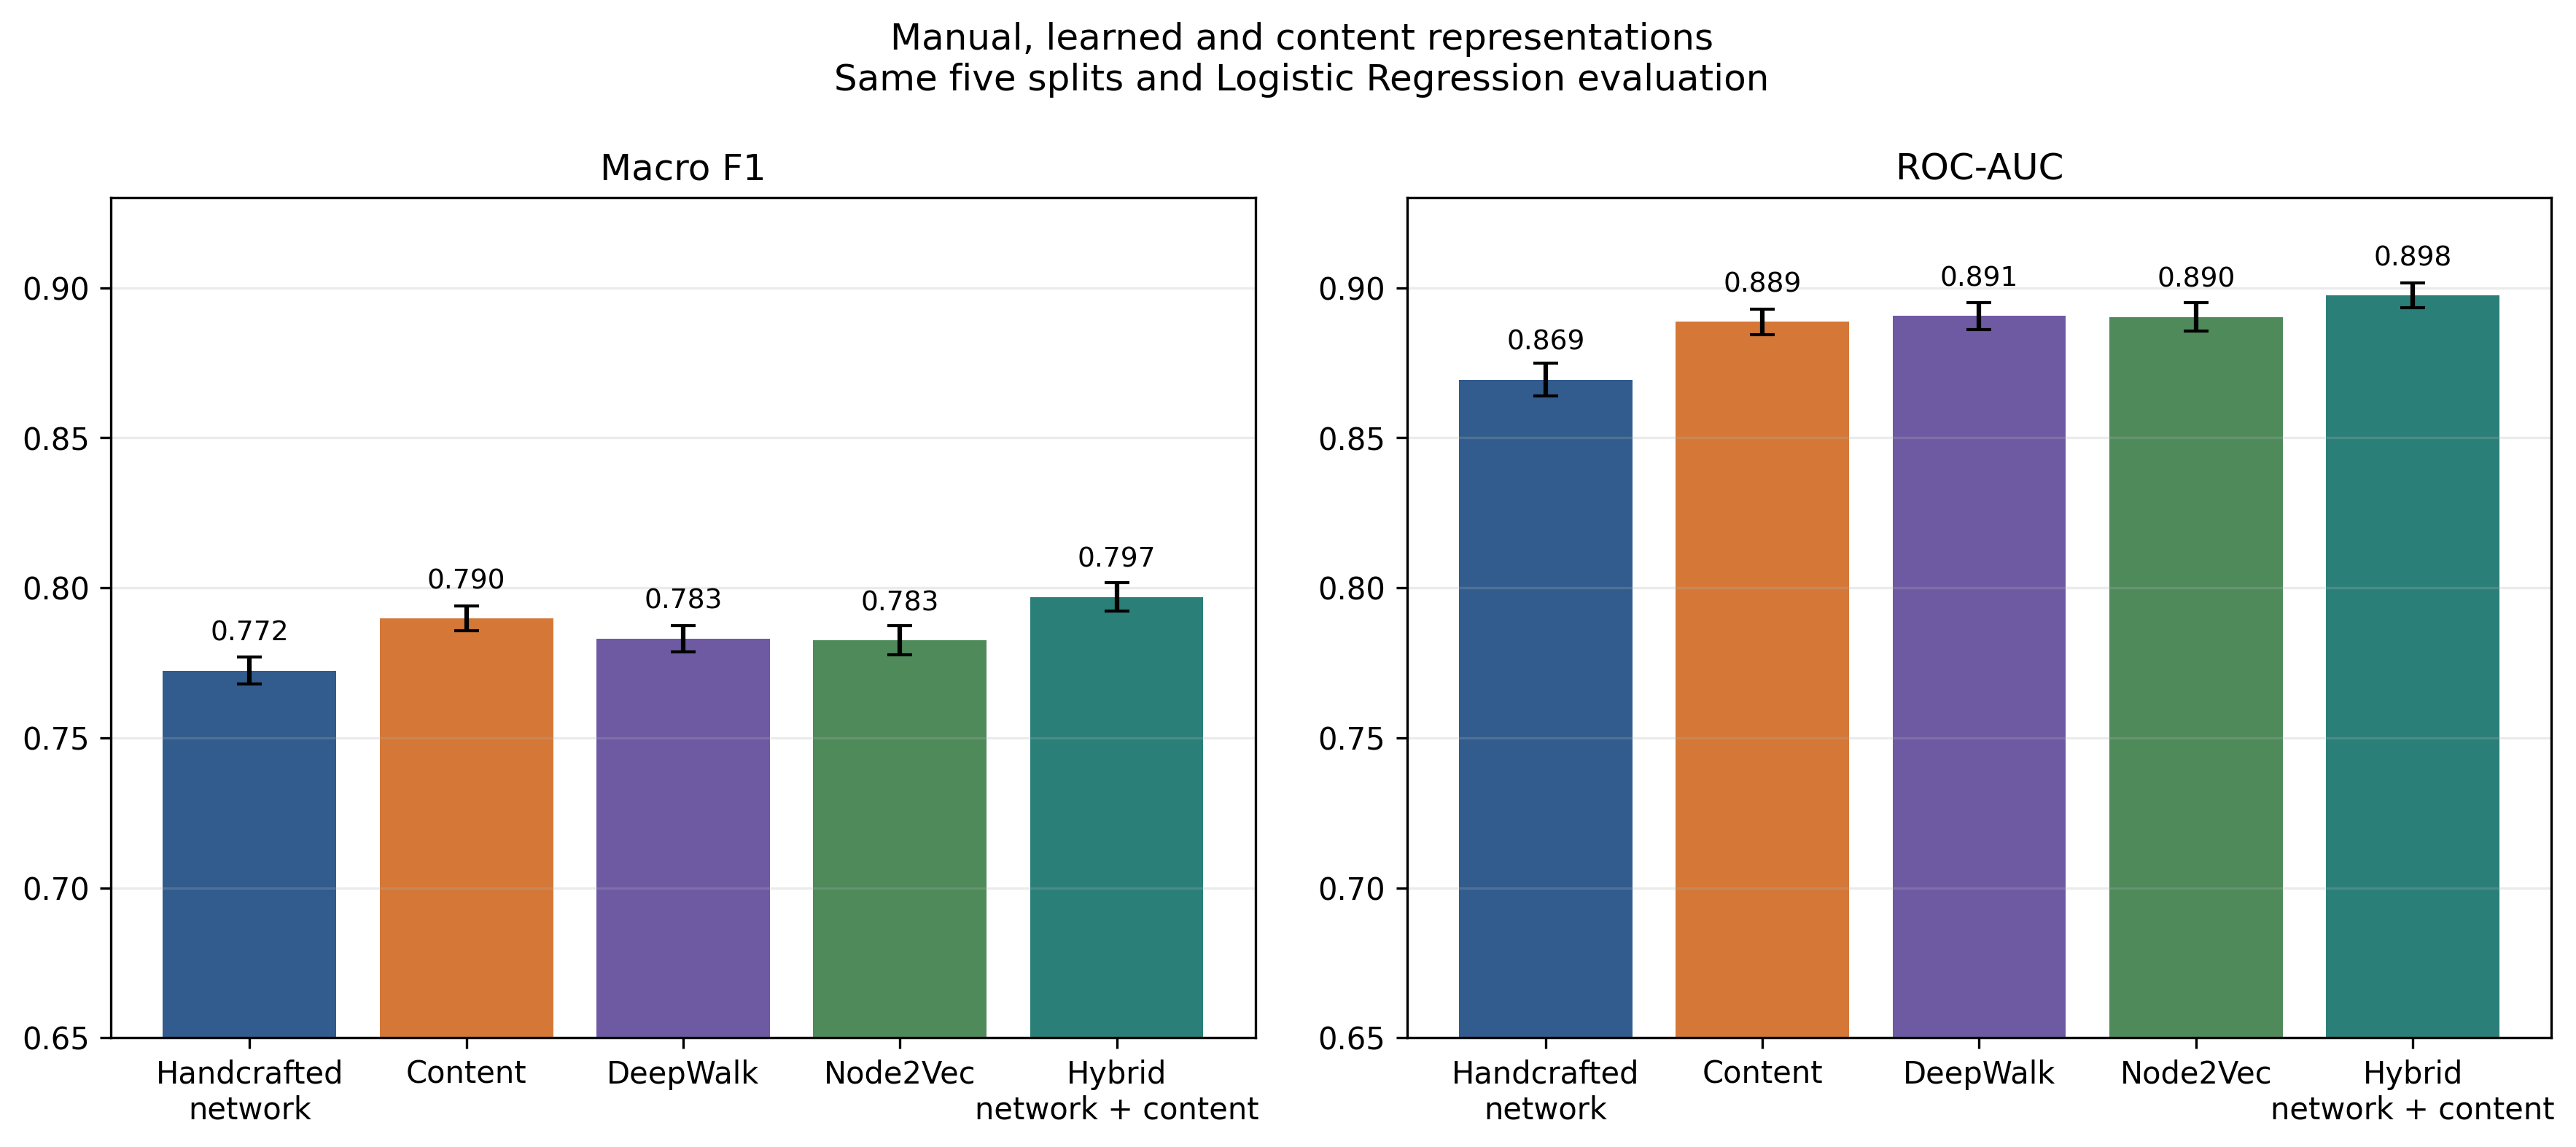

In [31]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'outputs/figures/representation_comparison.png')))

**Figure note.** Similar DeepWalk and Node2Vec scores show robust predictive value under this budget, while the combined models show that learned and handcrafted structure are not identical.

<h3>Conclusion for question 2</h3>

Content features work very well on their own, and the combined model works best. This means the graph adds useful information instead of only repeating the content signal.

<h2>Summary</h2>

In this notebook we added content features and graph embeddings to the same label-prediction task. We compared content-only, graph-only, combined features, DeepWalk, and Node2Vec. The results show which source of information helps most and whether combining sources is worth it. This gives a fuller picture than using only the handcrafted graph features from the previous notebook.